In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv(r'C:\Projects\NLP_Project\NLP-Project\data\geo-reviews-dataset-2023.csv')
df.head(10)

,address,name_ru,rating,rubrics,text
0,"Екатеринбург, ул. Московская / ул. Волгоградск...",Московский квартал,3.0,Жилой комплекс,Московский квартал 2.\nШумно : летом по ночам ...
1,"Московская область, Электросталь, проспект Лен...",Продукты Ермолино,5.0,Магазин продуктов;Продукты глубокой заморозки;...,"Замечательная сеть магазинов в общем, хороший ..."
2,"Краснодар, Прикубанский внутригородской округ,...",LimeFit,1.0,Фитнес-клуб,"Не знаю смутят ли кого-то данные правила, но я..."
3,"Санкт-Петербург, проспект Энгельса, 111, корп. 1",Snow-Express,4.0,Пункт проката;Прокат велосипедов;Сапсёрфинг,Хорошие условия аренды. \nДружелюбный персонал...
4,"Тверь, Волоколамский проспект, 39",Студия Beauty Brow,5.0,"Салон красоты;Визажисты, стилисты;Салон бровей...",Топ мастер Ангелина топ во всех смыслах ) Немн...
5,"Иркутская область, Черемхово, Первомайская ули...",Tele2,5.0,Оператор сотовой связи;Интернет-провайдер,"Приятное общение, все доступно объяснили, мне ..."
6,"Воронежская область, Богучарский район, М-4 До...",У тещи,4.0,Кафе,Глубинка страны во всех своих проявлениях. Асс...
7,"Пермь, улица Солдатова, 15",Smoking Park,5.0,Вейп-шоп;Магазин табака и курительных принадле...,"Лучший шоп на крохалях \nБольшоц ассортимент, ..."
8,"Москва, 4-й Кожевнический переулок, 4",Jinju,5.0,Кафе;Кофейня,"5 из 5🖤 Пил кофе и в Риме, и в Париже, но вку..."
9,"Москва, 4-й Кожевнический переулок, 4",Jinju,4.0,Кафе;Кофейня,"Не очень удобное расположение, от метро идти м..."


In [2]:
df['rating'].value_counts()

rating
5.0    390515
4.0     41160
1.0     34351
3.0     21686
2.0     12088
0.0       200
Name: count, dtype: int64

In [3]:
df_prepared = df[(df['rating'] <= 2.0) | (df['rating'] >= 4.0)].copy()

#drop duplicates
df_prepared = df_prepared.drop_duplicates(subset = ['text'], keep = 'first').copy()

#Creating target label
# if <= 2 then 1
# if >= 4 then 0

df_prepared['label'] = (df_prepared['rating'] <= 2).astype(int)
#drop index
df_prepared = df_prepared.reset_index(drop = True)

In [4]:
df_prepared.head(10)

,address,name_ru,rating,rubrics,text,label
0,"Московская область, Электросталь, проспект Лен...",Продукты Ермолино,5.0,Магазин продуктов;Продукты глубокой заморозки;...,"Замечательная сеть магазинов в общем, хороший ...",0
1,"Краснодар, Прикубанский внутригородской округ,...",LimeFit,1.0,Фитнес-клуб,"Не знаю смутят ли кого-то данные правила, но я...",1
2,"Санкт-Петербург, проспект Энгельса, 111, корп. 1",Snow-Express,4.0,Пункт проката;Прокат велосипедов;Сапсёрфинг,Хорошие условия аренды. \nДружелюбный персонал...,0
3,"Тверь, Волоколамский проспект, 39",Студия Beauty Brow,5.0,"Салон красоты;Визажисты, стилисты;Салон бровей...",Топ мастер Ангелина топ во всех смыслах ) Немн...,0
4,"Иркутская область, Черемхово, Первомайская ули...",Tele2,5.0,Оператор сотовой связи;Интернет-провайдер,"Приятное общение, все доступно объяснили, мне ...",0
5,"Воронежская область, Богучарский район, М-4 До...",У тещи,4.0,Кафе,Глубинка страны во всех своих проявлениях. Асс...,0
6,"Пермь, улица Солдатова, 15",Smoking Park,5.0,Вейп-шоп;Магазин табака и курительных принадле...,"Лучший шоп на крохалях \nБольшоц ассортимент, ...",0
7,"Москва, 4-й Кожевнический переулок, 4",Jinju,5.0,Кафе;Кофейня,"5 из 5🖤 Пил кофе и в Риме, и в Париже, но вку...",0
8,"Москва, 4-й Кожевнический переулок, 4",Jinju,4.0,Кафе;Кофейня,"Не очень удобное расположение, от метро идти м...",0
9,"Ростовская область, Таганрог, улица Чучева, 38",Kari ГИПЕР,5.0,Магазин обуви;Ювелирный магазин;Детские игрушк...,"Очень большой выбор обуви для всей семьи, по р...",0


In [5]:
df_prepared['label'].value_counts()

label
0    431560
1     46639
Name: count, dtype: int64

In [6]:
from sklearn.model_selection import train_test_split

#split data to train and test
df_train_val, df_test = train_test_split(
    df_prepared,
    test_size = 0.2,
    random_state = 42,
    stratify = df_prepared['label'] #saving proportion of target labels 
)
# splitting train data into training set and validation set
df_train, df_val = train_test_split(
    df_train_val,
    test_size = 0.125,
    random_state = 42,
    stratify= df_train_val['label']
)

df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

**Train Part**

In [7]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader 
from transformers import AutoModel, AutoTokenizer,get_linear_schedule_with_warmup
import torch.nn.functional as F
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import warnings
from tqdm.auto import tqdm
import os
import random
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve
import seaborn as sns
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

c:\Users\ASUS\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using model https://huggingface.co/intfloat/multilingual-e5-small

In [8]:
#Giving paramaters
MODEL_NAME = "intfloat/multilingual-e5-small"
BATCH_SIZE = 32
MAX_LENGTH = 64
NUM_EPOCHS = 10
RANDOM_SEED = 42

In [9]:
def seed_all(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_all(RANDOM_SEED)

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [11]:
text = "Hey There! I am Ramil and welcome to my project! Today you gonna see a NLP project based on Geo-reviews dataset!"
encoding = tokenizer(
    text,
    max_length = MAX_LENGTH,
    padding = 'max_length',
    truncation = True,
    return_tensors = 'pt'
)
print(encoding)

{'input_ids': tensor([[     0,  28240,   8622,     38,     87,    444,   8446,    379,    136,
          81907,     47,    759,  13452,     38,  38396,    398, 132294,   1957,
             10,    541,  37352,  13452,  35509,     98,  30152,      9, 132340,
              7,   2053,   3509,     38,      2,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])}


In [12]:
class TextDataset(Dataset):
    def __init__(self, df, tokenizer, max_length):
        self.labels = df['label'].tolist()
        
        self.encodings = tokenizer(
            df['text'].tolist(),
            max_length = max_length,
            padding = 'max_length',
            truncation = True,
            return_tensors = 'pt'
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        
        return {
            'input_ids': self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'label': torch.tensor(self.labels[idx], dtype=torch.float)
        }

In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_dataset = TextDataset(df_train, tokenizer, MAX_LENGTH)
val_dataset = TextDataset(df_val, tokenizer, MAX_LENGTH)
test_dataset = TextDataset(df_test, tokenizer, MAX_LENGTH)


In [14]:
train_dataset[150]

{'input_ids': tensor([     0,   1813,    103,  79311,     61,  58768,   7110,  20765,  73042,
              4,   3549, 119015, 214456,      4,     49,  96664,  27115, 206400,
            103,  25068,    227,      5,  48228,   3873, 119015,  22326,  38964,
          14468, 135534,  34887,      4,  21388, 214209,      6, 137418,      5,
           5560, 131503,    743,      5,      2,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1]),
 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
 'label': tensor(0.)}

In [15]:
train_loader = DataLoader(train_dataset, batch_size = BATCH_SIZE, shuffle = True)
val_loader = DataLoader(val_dataset, batch_size = BATCH_SIZE, shuffle = False)
test_loader = DataLoader(test_dataset,batch_size = BATCH_SIZE, shuffle = False)

In [16]:
batch = next(iter(train_loader))
batch

{'input_ids': tensor([[     0,   1721,  26958,  ...,  36562, 146038,      2],
         [     0, 212309,   2192,  ...,  41661,   9977,      2],
         [     0,   7762, 213683,  ...,      1,      1,      1],
         ...,
         [     0,   3858,    546,  ..., 158568, 228948,      2],
         [     0,   7796,     29,  ...,      4,    336,      2],
         [     0,  39663,  10758,  ...,   1200,   1996,      2]]),
 'attention_mask': tensor([[1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 0, 0, 0],
         ...,
         [1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 1, 1, 1]]),
 'label': tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0.])}

In [17]:
batch['input_ids'].shape
#256 batches and 64 max length of tokens

torch.Size([32, 64])

In [18]:
batch['attention_mask'].shape

torch.Size([32, 64])

In [19]:
batch['label'].shape

torch.Size([32])

Number of gradients for 1 epoch

In [20]:
len(train_loader)
#1308 batches

10461

In [21]:
class BERT_Model(nn.Module):
    def __init__(self, model_name = 'DeepPavlov/rubert-base-cased'):
        super().__init__()
        self.e5 = AutoModel.from_pretrained(model_name)
        self.classifier = nn.Linear(self.e5.config.hidden_size, 1) # binary classification

    def forward(self,input_ids,attention_mask):
        outputs = self.e5(input_ids = input_ids, attention_mask = attention_mask)
        pooled_output = outputs.last_hidden_state[:,0] # Taking embedding of the first token [CLS]
        logits = self.classifier(pooled_output)
        return logits.squeeze(-1)

In [22]:
class ESClassifier(nn.Module):
    def __init__(self, model_name = 'intfloat/multilingual-e5-small'):
        super().__init__()
        self.model = AutoModel.from_pretrained(model_name)
        print("embed_dimension = ", self.model.config.hidden_size)
        self.classifier = nn.Linear(self.model.config.hidden_size, 1)

    def mean_pooling(self,token_embeddings,attention_mask):
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(
            token_embeddings.size()).float()
        sum_embeddings = torch.sum(token_embeddings * input_mask_expanded,1)
        sum_mask = torch.clamp(input_mask_expanded.sum(1), min = 1e-9)
        return sum_embeddings / sum_mask

    def forward(self,input_ids,attention_mask):
        outputs = self.model(input_ids = input_ids, attention_mask = attention_mask)
        pooled_output = self.mean_pooling(outputs.last_hidden_state, attention_mask)
        logits = self.classifier(pooled_output)

        return logits.squeeze(-1)

In [23]:
model = ESClassifier(MODEL_NAME)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 21669.52it/s]

embed_dimension =  384


In [24]:
model

ESClassifier(
  (model): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(250037, 384, padding_idx=0)
      (position_embeddings): Embedding(512, 384)
      (token_type_embeddings): Embedding(2, 384)
      (LayerNorm): LayerNorm((384,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=384, out_features=384, bias=True)
              (key): Linear(in_features=384, out_features=384, bias=True)
              (value): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=384, out_features=384, bias=True)
              (LayerNorm): LayerNorm((384,), eps=1e-12, elementwise_af

In [25]:
def count_parameters(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total_params, trainable_params

In [26]:
count_parameters(model)

(117654145, 117654145)

In [27]:
def compute_metrics(predictions, labels,threshold = 0.5):
    predictions_binary = (predictions > threshold).astype(int)
    accuracy = accuracy_score(labels, predictions_binary)
    precision = precision_score(labels, predictions_binary)
    recall = recall_score(labels, predictions_binary)
    f1 = f1_score(labels, predictions_binary)
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

In [28]:
class FocalLoss(nn.Module):
    def __init__(self, alpha: torch.Tensor, gamma: float = 2,reduction: str = 'mean'):
        super().__init__()
        self.alpha = alpha.float()
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        assert inputs.shape == targets.shape, f'Shape mismatch: {inputs.shape} vs {targets.shape}'

        targets_long = targets.long()
        targets_float = targets.float()

        bce_loss = F.binary_cross_entropy_with_logits(
                inputs, targets_float, reduction = 'none'
        )

        p_t = torch.exp(-bce_loss)
        alpha = self.alpha.to(inputs.device)
        alpha_t = alpha.gather(0, targets_long.view(-1)).view_as(targets)
        focal_weight = (1 - p_t)** self.gamma

        loss = alpha_t * focal_weight * bce_loss

        if self.reduction == "mean":
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        else:
            return loss     

In [29]:
def train_model(model, train_loader,val_loader,device,num_epochs = 5):
    model.to(device)

    total_steps = len(train_loader) * num_epochs
    warmup_steps = int(0.05 * total_steps) 

    loss_func = FocalLoss(
        alpha = torch.tensor([0.5,1.0]),
        gamma = 2.5,
    )

    optimizer = AdamW(
        model.parameters(),
        lr = 3e-5,
        weight_decay = 0.01

    )

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps= warmup_steps,
        num_training_steps= total_steps
    )

    train_losses = []
    val_losses = []

    best_val_f1 = 0

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch + 1}/ sum{num_epochs}')
        # TRAIN
        model.train()
        total_train_loss = 0
        for batch in tqdm(train_loader, desc = f'Training', leave = False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            optimizer.zero_grad()
            outputs = model(input_ids, attention_mask)
            loss = loss_func(outputs, labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()

            total_train_loss += loss.item()
        train_losses.append(total_train_loss / len(train_loader))       

        #VALIDATION

        model.eval()
        total_val_loss = 0
        val_predictions = []
        val_labels = []

        with torch.no_grad():
            for batch in tqdm(val_loader, desc= f'Validation', leave= False):
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['label'].to(device)

                outputs = model(input_ids, attention_mask)

                loss = loss_func(outputs,labels)
                total_val_loss += loss.item()

                predictions = torch.sigmoid(outputs).cpu().numpy()
                val_predictions.extend(predictions)
                val_labels.extend(labels.cpu().numpy())
        val_losses.append(total_val_loss / len(val_loader))

        val_metrics = compute_metrics(np.array(val_predictions), np.array(val_labels))
        current_f1 = val_metrics['f1']
        val_acc = val_metrics['accuracy']

        print(f'Train loss: {train_losses[-1]:.4f} | Val loss: {val_losses[-1]:.4f} | val accuracy {val_acc:.3f} | val F1:{current_f1:.3f}')

        if current_f1 > best_val_f1:
            best_val_f1 = current_f1
            torch.save(model.state_dict(), 'best_model.pth')
            print("Model weight updated because of improved validation of f1 score")

    print(f'\nTraining complete best validation F1: {best_val_f1:.4f}')

    return model, train_losses, val_losses

In [34]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

final_model, train_l, val_l = train_model(
    model = model,
    train_loader = train_loader,
    val_loader = val_loader,
    device = device,
    num_epochs = 5,
)


Epoch 1/ sum5


Train loss: 0.0149 | Val loss: 0.0114 | val accuracy 0.969 | val F1:0.847
Model weight updated because of improved validation of f1 score

Epoch 2/ sum5


Train loss: 0.0104 | Val loss: 0.0112 | val accuracy 0.973 | val F1:0.864
Model weight updated because of improved validation of f1 score

Epoch 3/ sum5


Train loss: 0.0080 | Val loss: 0.0119 | val accuracy 0.972 | val F1:0.864

Epoch 4/ sum5


Train loss: 0.0059 | Val loss: 0.0144 | val accuracy 0.973 | val F1:0.862

Epoch 5/ sum5


Train loss: 0.0042 | Val loss: 0.0169 | val accuracy 0.973 | val F1:0.862

Training complete best validation F1: 0.8644


In [30]:
plt.figure(figsize = (10,6))
plt.plot(train_l, label = 'Training Loss', marker = 'o')
plt.plot(val_l, label = 'Validation Loss', marker = 's')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

NameError: name 'train_l' is not defined

<Figure size 1000x600 with 0 Axes>

In [31]:
# Loading final model to test 
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
model.load_state_dict(torch.load('best_model.pth', map_location = device))
model.to(device).eval()

final_predictions = []
final_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        outputs = model(input_ids,attention_mask)
        predictions = torch.sigmoid(outputs).cpu().numpy()

        final_predictions.extend(predictions)
        final_labels.extend(labels.cpu().numpy())

final_predictions = np.array(final_predictions).ravel()
final_labels = np.array(final_labels).ravel()

100%|██████████| 2989/2989 [00:52<00:00, 56.96it/s]


In [32]:
final_predictions

array([0.15420453, 0.6162911 , 0.2202059 , ..., 0.8660704 , 0.11476722,
       0.2649645 ], dtype=float32)

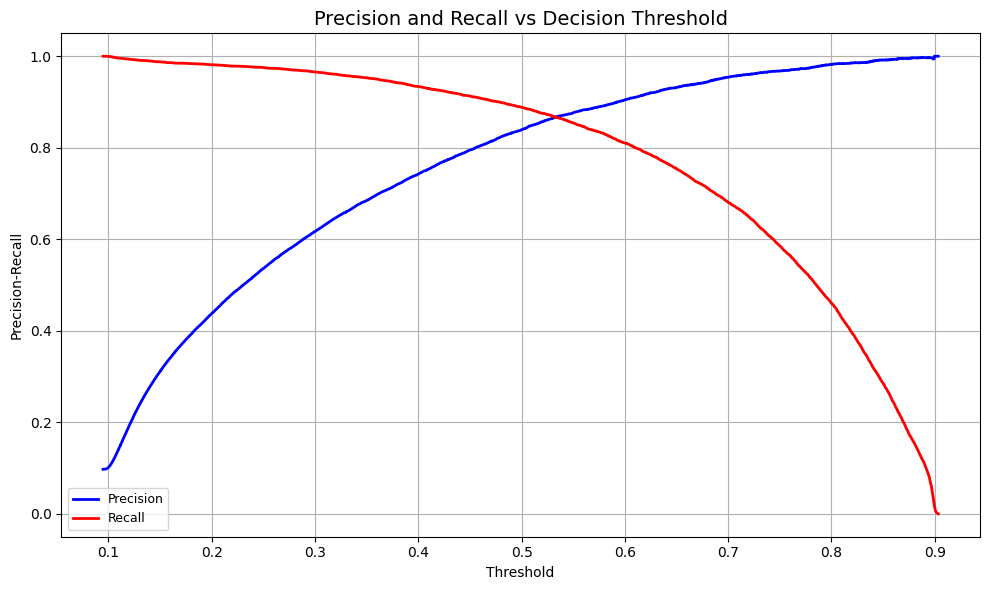

In [33]:
# Precision-Recall vs Threshold
precisions, recalls, thresholds = precision_recall_curve(final_labels, final_predictions)
plt.figure(figsize = (10,6))
plt.plot(thresholds, precisions[:-1], label = 'Precision', color = 'blue', linewidth = 2)
plt.plot(thresholds, recalls[:-1], label = 'Recall', color = 'red', linewidth= 2)
plt.xlabel('Threshold')
plt.ylabel('Precision-Recall')
plt.title('Precision and Recall vs Decision Threshold', fontsize = 14)
plt.legend(fontsize = 9)
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
differences = np.abs(precisions[:-1] - recalls[:-1])

optimal_idx = np.argmin(differences)

# 4. Extracting threshold value
exact_threshold = thresholds[optimal_idx]

print(f"Best Threshold Precision and Recall: {exact_threshold:.4f}")

Best Threshold Precision and Recall: 0.5325


In [35]:
threshold = 0.5325
final_predictions_binary = (final_predictions > threshold).astype(int)

#Classification Report

print(f'CLASSIFICATION REPORT (threshold={threshold})')
print(classification_report(final_labels, final_predictions_binary, digits = 2))

CLASSIFICATION REPORT (threshold=0.5325)
              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99     86312
         1.0       0.87      0.87      0.87      9328

    accuracy                           0.97     95640
   macro avg       0.93      0.93      0.93     95640
weighted avg       0.97      0.97      0.97     95640



CONFUSION MATRIX (threshold=0.5325)
[[85069  1243]
 [ 1244  8084]]


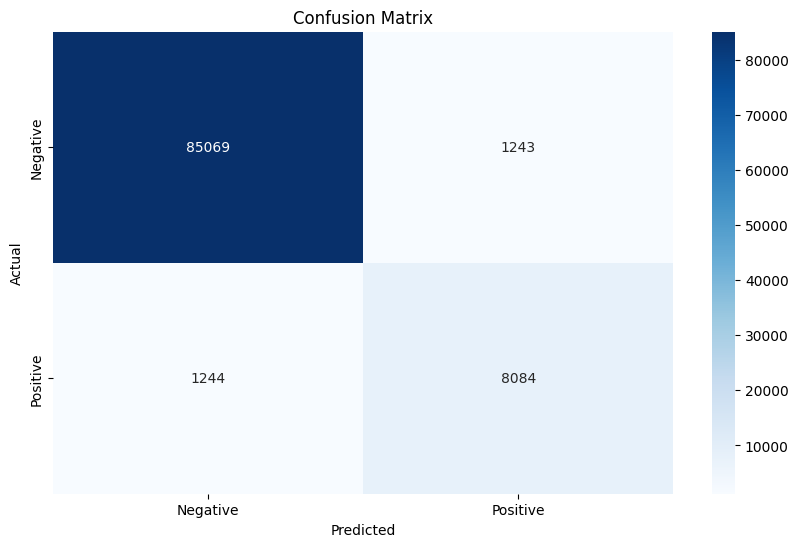

In [36]:
#Confusion Matrix
print(f'CONFUSION MATRIX (threshold={threshold})')
print(confusion_matrix(final_labels, final_predictions_binary))
plt.figure(figsize = (10,6))
sns.heatmap(confusion_matrix(final_labels, final_predictions_binary), fmt = 'd', annot = True, cmap = 'Blues'
            , xticklabels=['Negative', 'Positive']
            , yticklabels= ['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [37]:
df_test['model_score'] = final_predictions
df_test['predicted_label'] = (final_predictions > 0.5325).astype(int)
fp_df = df_test[(df_test['predicted_label'] == 1) & (df_test['label'] == 0)]
print(f'\n False Positive(FP){len(fp_df)}')
print("="*80)

for idx, row in fp_df.sample(min(5,len(fp_df))).iterrows():
    print(f"SCORE from the model: {row['model_score']:.4f}")
    print(f'Rating in the website:{row['rating']:.4f}')
    print(f'TEXT: {row['text'][:200]}...')
    print("-"*80)


 False Positive(FP)1243
SCORE from the model: 0.5493
Rating in the website:5.0000
TEXT: Очень нравилась мастер Эля ! Сказали больше там не работает, никто не знает куда он ушла ? 
...
--------------------------------------------------------------------------------
SCORE from the model: 0.7382
Rating in the website:5.0000
TEXT: Снимали квартиру на 24 этаже. Минусы - слышно соседей и в ветряный день громыхало просто все - закрытые окна, вентиляция, двери. Виды чумовые, лифт на -1 этаж это просто жесть. Фиг дождещься а потом ф...
--------------------------------------------------------------------------------
SCORE from the model: 0.7940
Rating in the website:4.0000
TEXT: Из трёх клиник этой сети, в которых я была, эта мне не понравилась. Ходила к лору, а у него не работал дисковод, чтобы посмотреть снимок. Врач дал понять, что сам решать этот вопрос не будет, пришлось...
--------------------------------------------------------------------------------
SCORE from the model: 0.8363
Rating 

In [38]:
fn_df = df_test[(df_test['predicted_label'] == 0 ) & (df_test['label'] == 1)]
print(f'\n False Negative(FN){len(fn_df)}')
print("="*80)

for idx, row in fn_df.sample(min(5,len(fn_df))).iterrows():
    print(f"SCORE from the model: {row['model_score']:.4f}")
    print(f'Rating in the website:{row['rating']:.4f}')
    print(f'TEXT: {row['text'][:200]}...')
    print("-"*80)


 False Negative(FN)1244
SCORE from the model: 0.1043
Rating in the website:1.0000
TEXT: Спасибо, все хорошо. Персонал прекрасный. Очень помогают и стараются помочь. Дизайнеры отлично работают. Делала сложный заказ - всем понравился. Время ожидания до 10 минут. Можно все приготовить, еще ...
--------------------------------------------------------------------------------
SCORE from the model: 0.1408
Rating in the website:2.0000
TEXT: Ходил на бизнес-ланч. Народа много, цена для размера и качества вполне приемлема. Порции излишне большие. Есть выбор первого и второго из четырёх вариантов и гарнира из двух вариантов. Блюда, по-домаш...
--------------------------------------------------------------------------------
SCORE from the model: 0.2063
Rating in the website:2.0000
TEXT: Много лет мне нравились магазины данной сети и ассортиментом и ценами. Всё развивается, и сейчас мне удобнее для покупок пользоваться интернет-версией (сайтом). На сайте OODJI красивые девушки - модел...
---------

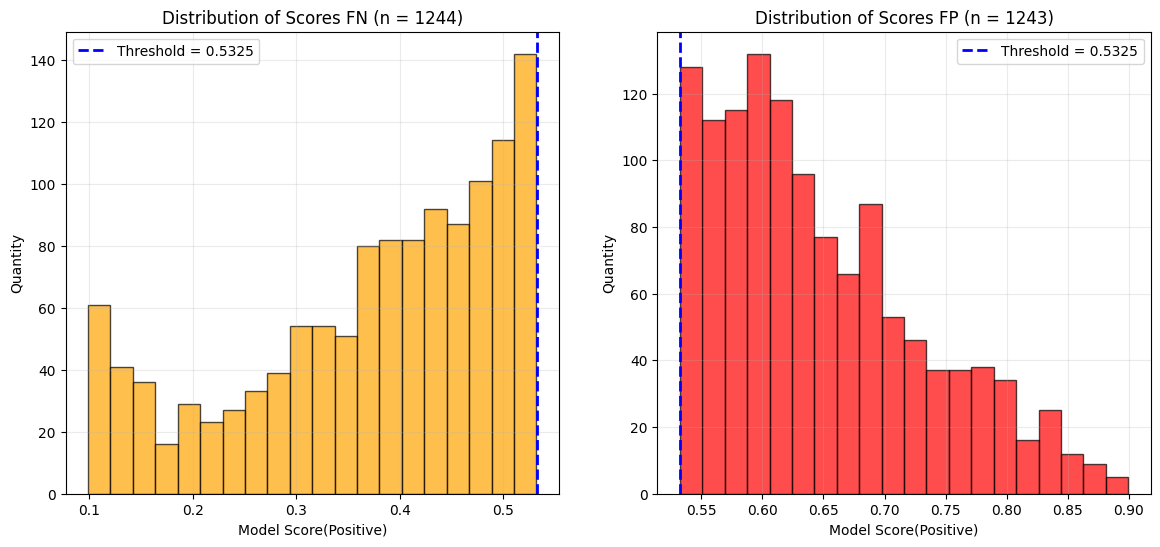

In [39]:
fig , axes = plt.subplots(1,2,figsize = (14,6))

if len(fp_df) > 0:
    axes[1].hist(fp_df['model_score'], bins = 20, color = 'red', alpha = 0.7,edgecolor = 'black')
    axes[1].axvline(x = 0.5325, color = 'blue', linestyle = '--', linewidth = 2, label = "Threshold = 0.5325")
    axes[1].set_xlabel("Model Score(Positive)")
    axes[1].set_ylabel("Quantity")
    axes[1].set_title(f'Distribution of Scores FP (n = {len(fp_df)})')
    axes[1].legend()
    axes[1].grid(True, alpha = 0.25)

if len(fn_df) > 0:
    axes[0].hist(fn_df['model_score'], bins = 20, color = 'orange', alpha = 0.7,edgecolor = 'black')
    axes[0].axvline(x = 0.5325, color = 'blue', linestyle = '--', linewidth = 2, label = "Threshold = 0.5325")
    axes[0].set_xlabel("Model Score(Positive)")
    axes[0].set_ylabel("Quantity")
    axes[0].set_title(f'Distribution of Scores FN (n = {len(fn_df)})')
    axes[0].legend()
    axes[0].grid(True, alpha = 0.25)

In [40]:
def predict_texts(model, tokenizer, texts, device):
    model.eval()
    predictions = []

    for text in texts:
        encoding = tokenizer(str(text),
                             max_length = MAX_LENGTH,
                             padding = 'max_length',
                             truncation = True,
                             return_tensors = 'pt')
        input_ids = encoding['input_ids'].to(device)
        attention_mask = encoding['attention_mask'].to(device)

        with torch.no_grad():
            output = model(input_ids, attention_mask)
            prob = torch.sigmoid(output).cpu().item()
            predictions.append(prob)
    return predictions

In [41]:
test_texts = [
    "Очень хорошее заведение!! Рекомендую",
    "Боже надеюсь больше меня здесь не будет",
    "ЭЭээээ че за жесть ежжи",
    "я даже незнаю нейтрально как то настроен",
    "ужас больше ни ногой в это место",
    'ну ок место'
]
predict_texts(model,tokenizer=tokenizer,texts = test_texts, device= device)

[0.11019333451986313,
 0.5599843263626099,
 0.6026756167411804,
 0.49785324931144714,
 0.8230699300765991,
 0.24582967162132263]

In [45]:
import onnx

In [46]:
class ModelWithReshape(nn.Module):
    def __init__(self, original_model):
        super().__init__()
        self.original_model = original_model

    def forward(self, input_ids,attention_mask):
        output = self.original_model(input_ids,attention_mask)
        output = output.unsqueeze(-1)
        return output

def convert_to_onnx(model, tokenizer, device, output_path = "model.onnx", max_length = 64):
    model.eval()

    wrapped_model = ModelWithReshape(model)
    wrapped_model.eval()

    dummy_text = 'dummy text for export'
    dummy_inputs = tokenizer(dummy_text, truncation= True, padding = 'max_length', max_length= max_length, return_tensors= 'pt')
    dummy_input_ids = dummy_inputs['input_ids'].to(device)
    dummy_attention_mask = dummy_inputs['attention_mask'].to(device)

    torch.onnx.export(
        wrapped_model,
        (dummy_input_ids, dummy_attention_mask),
        output_path,
        input_names=['input_ids','attention_mask'],
        output_names= ['output'],
        dynamic_axes= {
            'input_ids': {0: 'batch_size'},
            'attention_mask': {0: 'batch_size'},
            'output': {0: 'batch_size'}
        },
        opset_version= 14
    )

    print(f'Model with size [batch,1] is saved to {output_path}')

convert_to_onnx(model, tokenizer, device, "model.onnx", MAX_LENGTH)

Model with size [batch,1] is saved to model.onnx
